In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr

In [2]:
df = pd.read_csv('API_NE.GDI.FTOT.ZS_DS2_en_csv_v2_2996.csv', sep=',')

In [3]:
df

,Country Name,Country Code,Indicator Name,Indicator Code,1960,1961,1962,1963,1964,1965,...,2017,2018,2019,2020,2021,2022,2023,2024,2025,Unnamed: 70
0,Aruba,ABW,Gross fixed capital formation (% of GDP),NE.GDI.FTOT.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Africa Eastern and Southern,AFE,Gross fixed capital formation (% of GDP),NE.GDI.FTOT.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,21.731104,21.210017,21.355274,19.617590,19.405781,19.495412,19.582565,18.615082,17.931731,NaN
2,Afghanistan,AFG,Gross fixed capital formation (% of GDP),NE.GDI.FTOT.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,11.455628,12.986704,16.668472,15.243577,17.034535,NaN,NaN
3,Africa Western and Central,AFW,Gross fixed capital formation (% of GDP),NE.GDI.FTOT.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Angola,AGO,Gross fixed capital formation (% of GDP),NE.GDI.FTOT.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,28.705703,23.894114,24.451356,19.665675,16.219420,14.465370,12.421193,10.622754,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
261,Kosovo,XKX,Gross fixed capital formation (% of GDP),NE.GDI.FTOT.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,29.959525,31.711269,31.042639,29.706191,32.880725,32.504808,31.480512,31.645390,NaN,NaN
262,"Yemen, Rep.",YEM,Gross fixed capital formation (% of GDP),NE.GDI.FTOT.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,2.072285,6.176711,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
263,South Africa,ZAF,Gross fixed capital formation (% of GDP),NE.GDI.FTOT.ZS,17.474796,16.813354,16.191155,18.212305,19.742389,22.046063,...,16.398805,15.922167,15.468990,13.798361,13.109879,14.182485,14.934713,14.521736,13.878931,NaN
264,Zambia,ZMB,Gross fixed capital formation (% of GDP),NE.GDI.FTOT.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,38.807257,35.057599,35.756618,29.822851,28.510497,25.104325,26.437410,21.603216,NaN,NaN


In [4]:
df['Country Name'].unique();

In [5]:
df_US_EU = df[df['Country Name'].isin(['United States', 'European Union'])]

In [6]:
df_US_EU

,Country Name,Country Code,Indicator Name,Indicator Code,1960,1961,1962,1963,1964,1965,...,2017,2018,2019,2020,2021,2022,2023,2024,2025,Unnamed: 70
73,European Union,EUU,Gross fixed capital formation (% of GDP),NE.GDI.FTOT.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,20.498991,20.904110,21.990502,21.905861,21.805194,22.048645,22.114381,21.170276,21.314033,NaN
251,United States,USA,Gross fixed capital formation (% of GDP),NE.GDI.FTOT.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,20.989168,21.295997,21.331113,21.580278,21.293141,21.331212,21.377025,21.349834,NaN,NaN


In [7]:
df_US_EU = df_US_EU.reset_index(drop=True)

In [8]:
df_US_EU = df_US_EU.T

In [9]:
df_US_EU.columns = ['European Union', 'United States']

In [10]:
df_US_EU

,European Union,United States
Country Name,European Union,United States
Country Code,EUU,USA
Indicator Name,Gross fixed capital formation (% of GDP),Gross fixed capital formation (% of GDP)
Indicator Code,NE.GDI.FTOT.ZS,NE.GDI.FTOT.ZS
1960,NaN,NaN
...,...,...
2022,22.048645,21.331212
2023,22.114381,21.377025
2024,21.170276,21.349834
2025,21.314033,NaN


In [11]:
df_US_EU.drop(['Country Name', 'Country Code', 'Indicator Name', 'Indicator Code'], axis = 0, inplace = True)

In [12]:
df_US_EU

,European Union,United States
1960,NaN,NaN
1961,NaN,NaN
1962,NaN,NaN
1963,NaN,NaN
1964,NaN,NaN
...,...,...
2022,22.048645,21.331212
2023,22.114381,21.377025
2024,21.170276,21.349834
2025,21.314033,NaN


In [13]:
df_US_EU.info()

<class 'pandas.core.frame.DataFrame'>
Index: 67 entries, 1960 to Unnamed: 70
Data columns (total 2 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   European Union  56 non-null     object
 1   United States   55 non-null     object
dtypes: object(2)
memory usage: 1.6+ KB


In [14]:
df_US_EU['European Union'] = df_US_EU['European Union'].astype(float)
df_US_EU['United States'] = df_US_EU['United States'].astype(float)

In [15]:
df_US_EU.describe()

,European Union,United States
count,56.000000,55.000000
mean,22.666018,21.599389
std,1.979772,1.351563
min,19.552694,18.313937
25%,21.411976,20.765776
50%,22.144875,21.539901
75%,23.780221,22.495481
max,27.447027,24.426633


In [16]:
df_US_EU = df_US_EU.dropna()

In [17]:
df_US_EU.describe()

,European Union,United States
count,55.000000,55.000000
mean,22.690599,21.599389
std,1.989376,1.351563
min,19.552694,18.313937
25%,21.463332,20.765776
50%,22.175369,21.539901
75%,23.788393,22.495481
max,27.447027,24.426633


In [18]:
df_US_EU.info()

<class 'pandas.core.frame.DataFrame'>
Index: 55 entries, 1970 to 2024
Data columns (total 2 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   European Union  55 non-null     float64
 1   United States   55 non-null     float64
dtypes: float64(2)
memory usage: 1.3+ KB


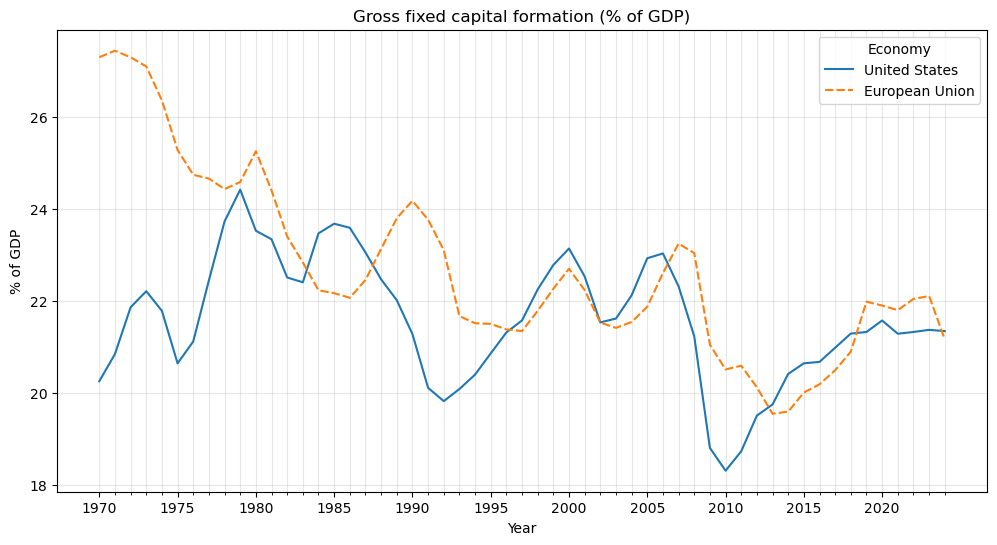

In [19]:
plt.figure(figsize=(12, 6))

ax = sns.lineplot(data=df_US_EU[['United States', 'European Union']])

plt.title('Gross fixed capital formation (% of GDP)')
plt.xlabel('Year')
plt.ylabel('% of GDP')

plt.legend(title='Economy')
plt.grid(alpha=0.3)

# Etykiety co pięć lat
ax.set_xticks(np.arange(0, len(df_US_EU.index), 5))
ax.set_xticklabels(df_US_EU.index[::5])

# Kreska osi i siatka dla każdego roku
ax.set_xticks(np.arange(len(df_US_EU.index)), minor=True)
ax.grid(which='minor', axis='x', alpha=0.3)

plt.show()

In [20]:
df_US_EU_1978_2023 = df_US_EU.loc['1978':'2023'].copy()

In [21]:
df_US_EU_1978_2023;

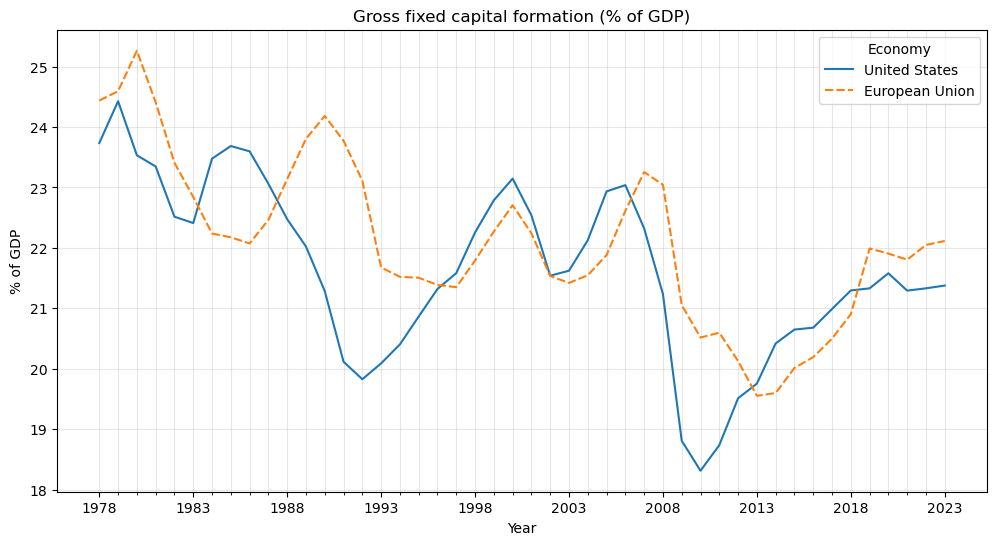

In [22]:
plt.figure(figsize=(12, 6))

ax = sns.lineplot(data=df_US_EU_1978_2023[['United States', 'European Union']])

plt.title('Gross fixed capital formation (% of GDP)')
plt.xlabel('Year')
plt.ylabel('% of GDP')

plt.legend(title='Economy')
plt.grid(alpha=0.3)

ax.set_xticks(np.arange(0, len(df_US_EU_1978_2023.index), 5))
ax.set_xticklabels(df_US_EU_1978_2023.index[::5])

ax.set_xticks(np.arange(len(df_US_EU_1978_2023.index)), minor=True)
ax.grid(which='minor', axis='x', alpha=0.3)

plt.show()

In [23]:
df_US_EU_1978_2023.info()

<class 'pandas.core.frame.DataFrame'>
Index: 46 entries, 1978 to 2023
Data columns (total 2 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   European Union  46 non-null     float64
 1   United States   46 non-null     float64
dtypes: float64(2)
memory usage: 2.1+ KB


In [24]:
df_US_EU_1978_2023.describe()

,European Union,United States
count,46.000000,46.000000
mean,22.099604,21.639154
std,1.351929,1.443804
min,19.552694,18.313937
25%,21.395557,20.726301
50%,22.019573,21.560089
75%,22.994056,22.725390
max,25.261768,24.426633


In [27]:
from scipy.stats import shapiro

for column in ['European Union', 'United States']:
    print(column, shapiro(df_US_EU_1978_2023[column]))

European Union ShapiroResult(statistic=np.float64(0.9807748078419768), pvalue=np.float64(0.6378034200757876))
United States ShapiroResult(statistic=np.float64(0.9784814154414769), pvalue=np.float64(0.5451589711642337))


In [28]:
for column in ['European Union', 'United States']:
    print(column, df_US_EU_1978_2023[column].autocorr(lag=1))

European Union 0.9019532537609528
United States 0.8953028853984322


In [29]:
df_changes = df_US_EU_1978_2023.diff().dropna()

In [30]:
from scipy.stats import pearsonr

r, p = pearsonr(
    df_changes['European Union'],
    df_changes['United States']
)

print(f'Pearson r: {r:.4f}')
print(f'p-value: {p:.4f}')

Pearson r: 0.3271
p-value: 0.0283


In [31]:
for column in ['European Union', 'United States']:
    print(column, df_changes[column].autocorr(lag=1))

European Union 0.44213458110865683
United States 0.48264597381317764


In [32]:
spearmanr(df_changes['European Union'], df_changes['United States'])

SignificanceResult(statistic=np.float64(0.15217391304347824), pvalue=np.float64(0.3183206210283531))

In [33]:
for column in ['European Union', 'United States']:
    print(column, df_changes[column].autocorr(lag=1))

European Union 0.44213458110865683
United States 0.48264597381317764


In [35]:
df_changes = df_US_EU_1978_2023.diff()
df_changes.describe()

,European Union,United States
count,45.000000,45.000000
mean,-0.051628,-0.052400
std,0.596750,0.660796
min,-1.989975,-2.425337
25%,-0.464534,-0.496199
50%,-0.014637,0.082705
75%,0.389230,0.358596
max,1.086392,1.064660


In [36]:
df_US_EU_1978_2023.std() / df_US_EU_1978_2023.mean() * 100

European Union    6.117436
United States     6.672186
dtype: float64

In [37]:
df_changes = df_US_EU_1978_2023.diff().dropna()

cv_changes = (
    df_changes.std() / df_changes.mean().abs() * 100
)

print(cv_changes)

European Union    1155.868676
United States     1261.052980
dtype: float64


In [38]:
df_changes

,European Union,United States
1979,0.155086,0.691592
1980,0.669049,-0.894755
1981,-0.852416,-0.184500
1982,-1.001775,-0.831275
1983,-0.564897,-0.104863
1984,-0.605175,1.064660
1985,-0.062137,0.209441
1986,-0.101702,-0.088200
1987,0.389230,-0.536082
1988,0.675939,-0.586201
